In [9]:
import numpy as np
import mne
import pickle
import functions as AvT
import matplotlib.pyplot as plt

1. Load events

In [38]:
directory_name = "labelled_data_200hz.nc condition=accuracy n_participants=19 baseline=(None, -0.15) steps=30 cycles=(3, 8) 2026-09-30"

with open(f"output/{directory_name}/tfr/tfr_dict_combined.pkl", 'rb') as file: tfr_dict_combined, _ = pickle.load(file)
with open(f"output/{directory_name}/tfr/tfr_dict_individual.pkl", 'rb') as file: tfr_dict_individual = pickle.load(file)


with open(f"output/{directory_name}/itc/itc_dict_combined.pkl", 'rb') as file: itc_dict_combined, _ = pickle.load(file)
with open(f"output/{directory_name}/itc/itc_dict_individual.pkl", 'rb') as file: itc_dict_individual = pickle.load(file)

2. Create permutation clusters

In [44]:
event_name = "4: response"
channel1 = 'Pz'

#TFR data
tfr_data = np.stack([x._data.astype('float16') for x in tfr_dict_individual[event_name]])
tfr_event = tfr_dict_individual[event_name][0]
tfr_data = np.average(tfr_data, axis=1) - tfr_data[:,tfr_event.info['ch_names'].index(channel1),:,:]


t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(tfr_data, n_permutations=1000, tail=0, n_jobs=-1, out_type='mask')
indices = np.where(cluster_pv <= 0.05)
if indices[0].shape[0] > 0: tfr_mask = np.stack([clusters[x] for x in indices[0]])
else: print("No mask found for TFR")

#ITC data
itc_data = np.stack([x._data.astype('float16') for x in itc_dict_individual[event_name]])
itc_event = itc_dict_individual[event_name][0]
itc_data = np.average(itc_data, axis=1) - itc_data[:,tfr_event.info['ch_names'].index(channel1),:,:]# - itc_data[:,tfr_event.info['ch_names'].index(channel2),:,:]

t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(itc_data, n_permutations=1000, tail=0, n_jobs=-1, out_type='mask')
indices = np.where(cluster_pv <= 0.05)
if indices[0].shape[0] > 0: itc_mask = np.stack([clusters[x] for x in indices[0]])
else: print("No mask found for ITC")



Using a threshold of 2.100922
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 10 clusters


C:\Users\arian\AppData\Local\Temp\ipykernel_3788\1200409885.py:10: RuntimeWarning: Provided stat_fun does not treat variables independently. Setting buffer_size to None.
  t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(tfr_data, n_permutations=1000, tail=0, n_jobs=-1, out_type='mask')


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

Using a threshold of 2.100922
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 78 clusters


C:\Users\arian\AppData\Local\Temp\ipykernel_3788\1200409885.py:20: RuntimeWarning: Provided stat_fun does not treat variables independently. Setting buffer_size to None.
  t_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_1samp_test(itc_data, n_permutations=1000, tail=0, n_jobs=-1, out_type='mask')


  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

3. Plot data

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


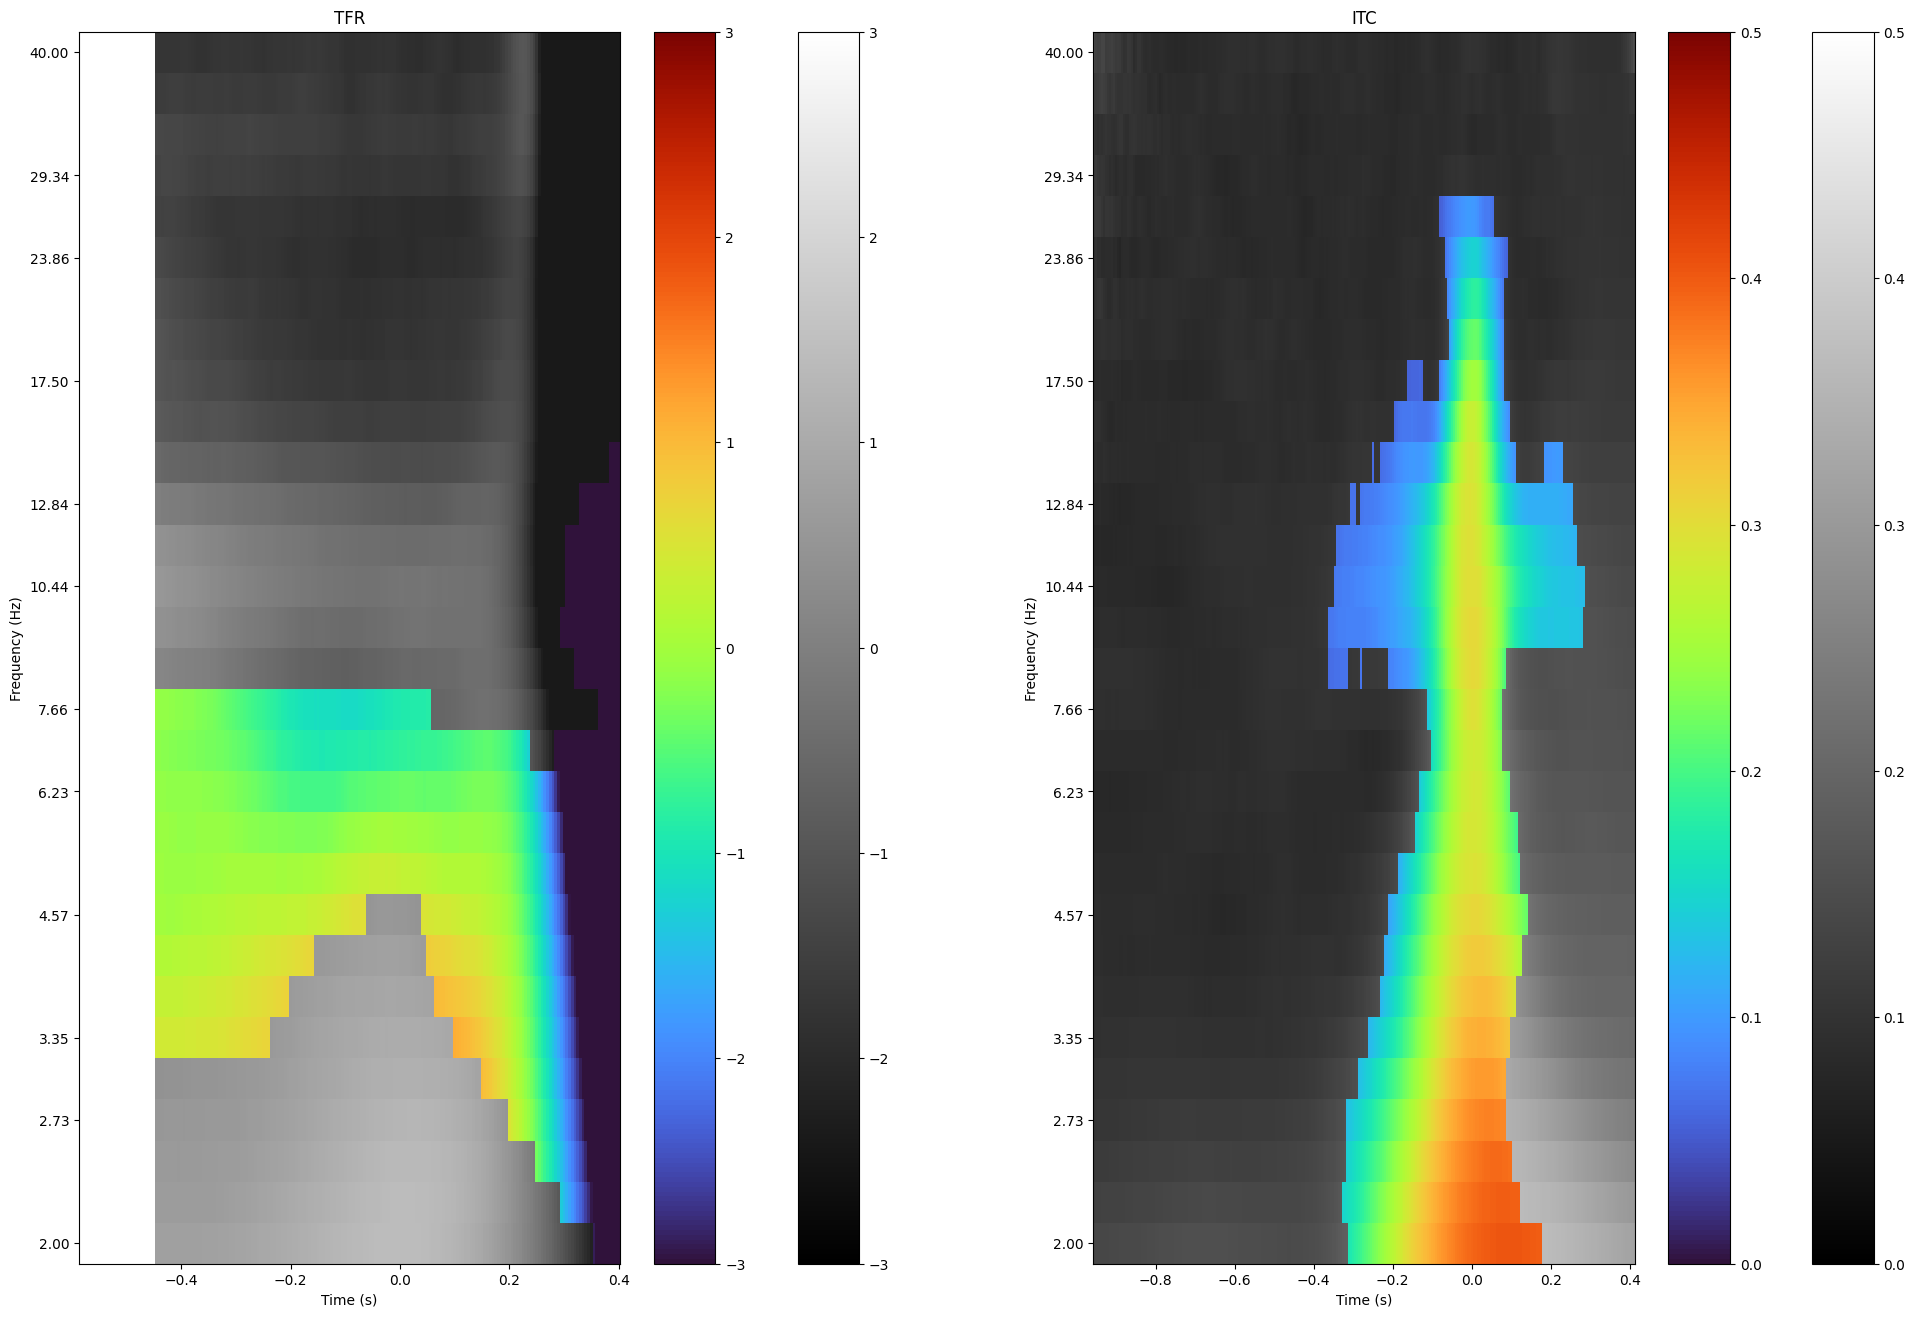

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(24,16))
ax[0].set_title("TFR")
ax[1].set_title("ITC")

#parameters                                                             #channels to be plotted
vmin, vmax = (-3, 3)                                                    #power


left, right = AvT.adaptive_xaxis(tfr_event, 'samples')                  #frequency (Hz)
tmin, tmax = AvT.adaptive_xaxis(tfr_event, 'time')

#plot total TFR
tfr_dict_combined[event_name].plot(axes=ax[0],  picks=[channel1], tmax=tmax, tmin=tmin, vlim=(vmin, vmax), show=False, cmap='gray', combine='mean')
tfr_dict_combined[event_name].plot(axes=ax[0],  picks=[channel1], tmax=tmax, tmin=tmin, vlim=(vmin, vmax), show=False, cmap='turbo', combine='mean', mask=tfr_mask[0][:, int(left):int(right)])


#parameters                                                             #channels to be plotted
vmin, vmax = (0, .5)                                                   #power


left, right = AvT.adaptive_xaxis(itc_event, 'samples')                  #frequency (Hz)
tmin, tmax = AvT.adaptive_xaxis(itc_event, 'time')

#plot total TFR
itc_dict_combined[event_name].plot(axes=ax[1], picks=[channel1], tmax=tmax, tmin=tmin, vlim=(vmin, vmax), show=False, cmap='gray', combine='mean')
itc_dict_combined[event_name].plot(axes=ax[1], picks=[channel1], tmax=tmax, tmin=tmin, vlim=(vmin, vmax), show=False, cmap='turbo', combine='mean', mask=itc_mask[0][:, int(left):int(right)])


plt.show()